# The regions do not sum to the forecast: seven ways to make them add up, scored

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phoebefu6/phoebe-the-builder/blob/main/data-quality-governance/forecast-reconciliation/demo.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/phoebefu6/phoebe-the-builder/main?labpath=data-quality-governance/forecast-reconciliation/demo.ipynb)

Finance has a national forecast, each region has its own, each store has its own, and they do not add up. The usual
fix is to pick one level and force the others to match it. This notebook builds a fictional retailer (4 regions,
12 stores), forecasts every series on its own, makes the numbers add up seven ways, and scores each way at every
level against the 12 months that actually happened.

1. The engine
2. Why the numbers do not add up
3. Seven ways to make them add up
4. Which method wins where
5. The check that passes for the worst method
6. What no reconciliation can fix
7. The chart
8. Try your own

## 1. The engine

Extracted from `explore.py` and `evidence.py` at build time. Seeded (`Generator(211)`), every store fictional, and
every number below matches `evidence.txt` exactly. `S` is the summing matrix: it turns 12 store numbers into all 17.
Reconciliation is one line, `S @ G @ yhat`; the methods differ only in `G`.

In [1]:
from __future__ import annotations

import json
from typing import Dict, List

import matplotlib.pyplot as plt
import numpy as np


class _E:  # evidence.py refers to the engine as E
    pass

SEED = 211


T, H = 48, 12


REGIONS = ["North", "South", "East", "West"]


STORES_PER = 3


LEVELS = ["total", "region", "store"]


METHODS = ["base", "bottom_up", "top_down_hist", "prorate", "ols", "wls", "mint_shrink"]


N_SEEDS = 30


def summing_matrix() -> np.ndarray:
    """Rows: total, 4 regions, 12 stores. Columns: 12 stores."""
    nb = len(REGIONS) * STORES_PER
    S = [np.ones(nb)]
    for r in range(len(REGIONS)):
        S.append(np.array([1.0 if j // STORES_PER == r else 0.0 for j in range(nb)]))
    S.extend(np.eye(nb))
    return np.array(S)


def level_rows() -> Dict[str, List[int]]:
    return {"total": [0], "region": list(range(1, 1 + len(REGIONS))),
            "store": list(range(1 + len(REGIONS), 1 + len(REGIONS) + len(REGIONS) * STORES_PER))}


def make_world(seed: int = SEED, shock: float = 0.0, t_train: int = T) -> dict:
    """Store sales = level x growth x season x noise. Noise = national + regional + store shocks (correlated).
    Growth differs by store, so the mix drifts. `shock` cuts one region's stores in the 12 test months only."""
    g = np.random.default_rng(seed)
    nb = len(REGIONS) * STORES_PER
    n = t_train + H
    t = np.arange(n)
    level = g.uniform(80, 220, nb)
    growth = g.normal(0.004, 0.008, nb)
    amp = g.uniform(0.05, 0.25, len(REGIONS))
    phase = g.uniform(0, 12, len(REGIONS))
    nat = g.normal(0, 0.03, n)
    reg = g.normal(0, 0.05, (len(REGIONS), n))
    bottom = np.zeros((nb, n))
    for j in range(nb):
        r = j // STORES_PER
        season = 1 + amp[r] * np.sin(2 * np.pi * (t - phase[r]) / 12)
        noise = nat + reg[r] + g.normal(0, 0.10, n)
        bottom[j] = level[j] * np.exp(growth[j] * t) * season * np.exp(noise)
    hit = None
    if shock:
        hit = int(g.integers(len(REGIONS)))
        for j in range(hit * STORES_PER, (hit + 1) * STORES_PER):
            bottom[j, t_train:] *= 1 - shock
    S = summing_matrix()
    return {"S": S, "y": S @ bottom, "bottom": bottom, "T": t_train, "shock_region": hit}


def design(n: int) -> np.ndarray:
    t = np.arange(n)
    return np.column_stack([np.ones_like(t), t] + [(t % 12 == m).astype(float) for m in range(1, 12)]).astype(float)


def base_forecasts(w: dict, log: bool = True) -> tuple:
    """Each series on its own: regression on intercept + trend + 11 month dummies, fitted to log sales (growth is
    multiplicative). Returns (forecast n x H, in-sample residuals n x T). log=False fits the raw scale instead."""
    Tn = w["T"]
    X = design(Tn + H)
    Xtr, Xte = X[:Tn], X[Tn:]
    y = w["y"][:, :Tn]
    tr = np.log if log else (lambda a: a)
    inv = np.exp if log else (lambda a: a)
    beta, *_ = np.linalg.lstsq(Xtr, tr(y).T, rcond=None)
    return inv(Xte @ beta).T, y - inv(Xtr @ beta).T


def shrink_cov(res: np.ndarray) -> np.ndarray:
    """Schafer-Strimmer shrinkage of the residual covariance toward its diagonal (as in MinT-shrink)."""
    e = res.T - res.T.mean(0)
    n = e.shape[0]
    cov = e.T @ e / n
    sd = np.sqrt(np.diag(cov))
    z = e / sd
    cor = z.T @ z / n
    wv = np.einsum("ti,tj->tij", z, z)
    var_cor = n / (n - 1) ** 3 * ((wv - wv.mean(0)) ** 2).sum(0)
    off = ~np.eye(cor.shape[0], dtype=bool)
    lam = float(np.clip(var_cor[off].sum() / (cor[off] ** 2).sum(), 0, 1))
    shrunk = lam * np.eye(cor.shape[0]) + (1 - lam) * cor
    np.fill_diagonal(shrunk, 1.0)
    return shrunk * np.outer(sd, sd)


def reconcile(w: dict, yhat: np.ndarray, res: np.ndarray, method: str) -> np.ndarray:
    S, rows = w["S"], level_rows()
    reg, sto = rows["region"], rows["store"]
    if method == "base":
        return yhat.copy()
    if method == "bottom_up":
        return S @ yhat[sto]
    if method == "top_down_hist":  # average historical share of each store in the total
        share = (w["y"][sto, : w["T"]] / w["y"][0, : w["T"]]).mean(1)
        return S @ np.outer(share, yhat[0])
    if method == "prorate":  # scale the pieces to the agreed number above them, level by level
        r = yhat[0] * yhat[reg] / yhat[reg].sum(0)
        b = np.zeros((len(sto), H))
        for i in range(len(reg)):
            kids = [k for k in range(len(sto)) if S[reg[i], k]]
            b[kids] = r[i] * yhat[[sto[k] for k in kids]] / yhat[[sto[k] for k in kids]].sum(0)
        return S @ b
    if method == "ols":
        Wi = np.eye(S.shape[0])
    elif method == "wls":  # structural scaling: variance proportional to the number of stores underneath
        Wi = np.diag(1 / S.sum(1))
    elif method == "mint_shrink":
        Wi = np.linalg.inv(shrink_cov(res))
    else:
        raise ValueError(method)
    G = np.linalg.solve(S.T @ Wi @ S, S.T @ Wi)
    return S @ (G @ yhat)


def rmse_by_level(w: dict, yt: np.ndarray) -> Dict[str, float]:
    """RMSE per series over the 12 test months, averaged within each level."""
    act = w["y"][:, w["T"]:]
    e = np.sqrt(((yt - act) ** 2).mean(1))
    return {lv: float(e[ix].mean()) for lv, ix in level_rows().items()}


def coherence_gap(w: dict, yt: np.ndarray) -> float:
    """Largest |parent - sum of children| as a share of the total forecast, over the horizon."""
    S, rows = w["S"], level_rows()
    implied = S @ yt[rows["store"]]
    return float(np.abs(yt - implied).max() / yt[0].mean())


def run(w: dict) -> dict:
    yhat, res = base_forecasts(w)
    out = {}
    for m in METHODS:
        yt = reconcile(w, yhat, res, m)
        out[m] = {"rmse": rmse_by_level(w, yt), "gap": coherence_gap(w, yt), "fc": yt}
    base = out["base"]["rmse"]
    for m in METHODS:
        out[m]["vs_base"] = {lv: out[m]["rmse"][lv] / base[lv] - 1 for lv in LEVELS}
    return out


def study(seed: int = SEED) -> dict:
    w = make_world(seed)
    r = run(w)
    rows = level_rows()
    yhat, _ = base_forecasts(w)
    reg_sum = yhat[rows["region"]].sum(0)
    sto_sum = yhat[rows["store"]].sum(0)
    return {
        "methods": {m: {"rmse": v["rmse"], "vs_base": v["vs_base"], "gap": v["gap"]} for m, v in r.items()},
        "raw_scale_gap": coherence_gap(w, base_forecasts(w, log=False)[0]),
        "base_regions_vs_total": float(np.abs(reg_sum - yhat[0]).max() / yhat[0].mean()),
        "base_stores_vs_total": float(np.abs(sto_sum - yhat[0]).max() / yhat[0].mean()),
        "share_drift": float(np.abs(w["bottom"][:, -H:].sum(1) / w["bottom"][:, -H:].sum()
                                    - w["bottom"][:, :T].sum(1) / w["bottom"][:, :T].sum()).sum() / 2),
        "total_actual": float(w["y"][0, T:].sum()),
        "regions_actual": [float(x) for x in w["y"][level_rows()["region"], T:].sum(1)],
        "regions_fc": {m: [float(x) for x in v["fc"][level_rows()["region"]].sum(1)] for m, v in r.items()},
    }


def seeds(n: int = N_SEEDS, shock: float = 0.0, t_train: int = T) -> dict:
    """Across n worlds: mean change vs base per level, and how often each method beats base at EVERY level."""
    acc = {m: {lv: [] for lv in LEVELS} for m in METHODS}
    allwin = {m: 0 for m in METHODS}
    best = {lv: {m: 0 for m in METHODS} for lv in LEVELS}
    bias = {"base": [], "bottom_up": []}
    for s in range(1, n + 1):
        w = make_world(1000 + s, shock=shock, t_train=t_train)
        r = run(w)
        act = w["y"][0, w["T"]:].sum()
        for m in bias:
            bias[m].append(float(r[m]["fc"][0].sum() / act - 1))
        for m in METHODS:
            for lv in LEVELS:
                acc[m][lv].append(r[m]["vs_base"][lv])
            allwin[m] += all(r[m]["vs_base"][lv] < 0 for lv in LEVELS)
        for lv in LEVELS:
            best[lv][min(METHODS, key=lambda m: r[m]["rmse"][lv])] += 1
    return {"n": n, "mean": {m: {lv: float(np.mean(v)) for lv, v in d.items()} for m, d in acc.items()},
            "all_levels_better": allwin, "best_count": best,
            "total_bias": {m: float(np.median(v)) for m, v in bias.items()}}


def shock_study(shock: float = 0.15, n: int = N_SEEDS) -> dict:
    """A cut nobody's history contains: how wrong is the shocked region under each method?"""
    errs = {m: [] for m in METHODS}
    for s in range(1, n + 1):
        w = make_world(1000 + s, shock=shock)
        r = run(w)
        i = level_rows()["region"][w["shock_region"]]
        act = w["y"][i, w["T"]:].sum()
        for m in METHODS:
            errs[m].append(float(r[m]["fc"][i].sum() / act - 1))
    return {"shock": shock, "n": n, "median_bias": {m: float(np.median(v)) for m, v in errs.items()},
            "min_bias": {m: float(np.min(v)) for m, v in errs.items()}}


E = _E()
E.__dict__.update(globals())

def pct(x: float) -> str:
    return f"{100 * x:+.1f}%"


def lines(r: dict, s: dict, sh: dict) -> List[str]:
    out: List[str] = []
    w = out.append
    w(f"forecast-reconciliation evidence  (fictional retailer: 1 total, {len(E.REGIONS)} regions, "
      f"{len(E.REGIONS) * E.STORES_PER} stores; {E.T} months of history, {E.H} months scored; "
      f"seeded Generator({E.SEED}), {s['n']} more worlds for the spread; every store fictional)")
    w("")
    w("1. Why the numbers do not add up")
    w(f"same linear model on every series, raw scale: largest gap      {100 * r['raw_scale_gap']:.2f}% of the total")
    w(f"log-scale model on every series: regions vs national forecast  {100 * r['base_regions_vs_total']:.2f}%")
    w(f"log-scale model on every series: stores vs national forecast   {100 * r['base_stores_vs_total']:.2f}%")
    w(f"store mix moved between history and the scored year           {100 * r['share_drift']:.1f}% of sales changed hands")
    w("")
    w("2. Seven ways to make them add up, RMSE change vs the unreconciled forecasts (minus = better)")
    w(f"{'method':<15}{'adds up':>8}{'total':>9}{'region':>9}{'store':>9}   {'30 worlds: total':>17}{'region':>9}"
      f"{'store':>9}{'better at all 3':>17}")
    for k in E.METHODS:
        a, m = r["methods"][k], s["mean"][k]
        adds = "yes" if a["gap"] < 1e-9 else "NO"
        w(f"{k:<15}{adds:>8}{pct(a['vs_base']['total']):>9}{pct(a['vs_base']['region']):>9}"
          f"{pct(a['vs_base']['store']):>9}   {pct(m['total']):>17}{pct(m['region']):>9}{pct(m['store']):>9}"
          f"{s['all_levels_better'][k]:>14} / {s['n']}")
    w("base = each series forecast on its own; bottom_up = sum the store forecasts; top_down_hist = split the national "
      "forecast by each store's average historical share; prorate = scale each level to the number above it; ols / "
      "wls / mint_shrink = least-squares reconciliation with identity, structural and shrunk-residual weights")
    w("")
    w("3. Which method wins where, across the worlds")
    for lv in E.LEVELS:
        bc = s["best_count"][lv]
        top = sorted(bc, key=lambda m: -bc[m])[:3]
        w(f"lowest {lv} RMSE   " + "   ".join(f"{m} {bc[m]}" for m in top) + f"   (of {s['n']})")
    tb = s["total_bias"]
    w(f"median bias of the national number   own model {pct(tb['base'])}   sum of store forecasts {pct(tb['bottom_up'])}")
    w("Stores grow at different rates; their sum is not one exponential, so the national log model under-forecasts.")
    w("")
    w("4. The check that passes for the worst method")
    td = r["methods"]["top_down_hist"]
    w(f"top_down_hist adds up exactly, and its region RMSE is {pct(td['vs_base']['region'])}, store "
      f"{pct(td['vs_base']['store'])} vs base")
    w("'Do the regions sum to the forecast?' passes for all six reconciled methods; it tests arithmetic, not accuracy.")
    w("")
    w("5. What no reconciliation can fix")
    w(f"one region's sales cut {100 * sh['shock']:.0f}% in the scored year, a cut no history contains ({sh['n']} worlds)")
    w("median over-forecast of the cut region   " + "   ".join(
        f"{m} {pct(sh['median_bias'][m])}" for m in ["base", "bottom_up", "wls", "mint_shrink"]))
    w("Every method redistributes the same forecasts; none of them contains the cut. Coherent and wrong.")
    return out


def main() -> None:
    r = E.study()
    s = E.seeds()
    sh = E.shock_study()
    json.dump({**r, "seeds": s, "shock": sh}, open("results.json", "w"), indent=1)
    text = "\n".join(lines(r, s, sh)) + "\n"
    open("evidence.txt", "w").write(text)
    print(text)

In [2]:
r = study()
s = seeds()
sh = shock_study()
out = lines(r, s, sh)
section = lambda n: [l for l in "\n".join(out).split(f"\n{n}. ")[1].split("\n\n")[0].splitlines()]
print(out[0])

forecast-reconciliation evidence  (fictional retailer: 1 total, 4 regions, 12 stores; 48 months of history, 12 months scored; seeded Generator(211), 30 more worlds for the spread; every store fictional)


## 2. Why the numbers do not add up

A linear model with the same inputs on every series adds up by construction: sums pass straight through it. The gap
appears as soon as any level is modelled differently. Here every series is fitted on the log scale (growth is
multiplicative), and the regions miss the national forecast by up to 1.75%, the stores by 2.63%.

In [3]:
print("\n".join(section(1)))

Why the numbers do not add up
same linear model on every series, raw scale: largest gap      0.00% of the total
log-scale model on every series: regions vs national forecast  1.75%
log-scale model on every series: stores vs national forecast   2.63%
store mix moved between history and the scored year           9.1% of sales changed hands


## 3. Seven ways to make them add up

Every reconciled method adds up exactly. Accuracy is another matter. Splitting the national number by historical
shares makes the region forecasts +77.6% worse on average, because the store mix moved. Least-squares methods
(WLS, MinT) gain most at the top, a few percent, and give back a little at the stores. No method beats the
unreconciled forecasts at all three levels in more than 2 of 30 worlds.

In [4]:
print("\n".join(section(2)))

Seven ways to make them add up, RMSE change vs the unreconciled forecasts (minus = better)
method          adds up    total   region    store    30 worlds: total   region    store  better at all 3
base                 NO    +0.0%    +0.0%    +0.0%               +0.0%    +0.0%    +0.0%             0 / 30
bottom_up           yes    -6.2%    -1.5%    +0.0%               -7.2%    -0.9%    +0.0%             0 / 30
top_down_hist       yes    +0.0%  +102.6%   +99.7%               +0.0%   +77.6%   +89.5%             0 / 30
prorate             yes    +0.0%    +1.7%    +1.7%               +0.0%    +1.7%    +1.4%             0 / 30
ols                 yes    -1.2%    +1.0%    +1.2%               -1.8%    +0.9%    +1.6%             0 / 30
wls                 yes    -3.4%    -0.2%    +0.7%               -5.0%    -0.3%    +0.7%             2 / 30
mint_shrink         yes    -4.7%    -0.7%    +0.4%               -5.8%    -0.5%    +0.4%             2 / 30
base = each series forecast on its own; bottom_

## 4. Which method wins where

The textbook answer is MinT. In these worlds bottom-up has the lowest national error in 23 of 30, because the
national model is the weaker forecast: stores grow at different rates, their sum is not one exponential, and the
national log model under-forecasts. The best method depends on which level your forecasts are good at, and that is
an empirical question for your own backtest.

In [5]:
print("\n".join(section(3)))

Which method wins where, across the worlds
lowest total RMSE   bottom_up 23   ols 2   wls 2   (of 30)
lowest region RMSE   bottom_up 15   base 8   mint_shrink 4   (of 30)
lowest store RMSE   base 16   prorate 7   mint_shrink 6   (of 30)
median bias of the national number   own model -2.4%   sum of store forecasts -0.8%
Stores grow at different rates; their sum is not one exponential, so the national log model under-forecasts.


## 5. The check that passes for the worst method

"Do the regions sum to the forecast?" is the check every planning pack runs. It passes for every reconciled method,
including the one that doubles the region error in this world. It tests arithmetic, not accuracy.

In [6]:
print("\n".join(section(4)))

The check that passes for the worst method
top_down_hist adds up exactly, and its region RMSE is +102.6%, store +99.7% vs base
'Do the regions sum to the forecast?' passes for all six reconciled methods; it tests arithmetic, not accuracy.


## 6. What no reconciliation can fix

This is the negative result. One region loses 15% of its sales in the scored year, a cut no history contains. Every
method over-forecasts it by roughly the same amount, because reconciliation only redistributes the forecasts it is
given. The numbers add up and they are all wrong.

In [7]:
print("\n".join(section(5)))

What no reconciliation can fix
one region's sales cut 15% in the scored year, a cut no history contains (30 worlds)
median over-forecast of the cut region   base +14.3%   bottom_up +15.7%   wls +14.7%   mint_shrink +14.9%
Every method redistributes the same forecasts; none of them contains the cut. Coherent and wrong.


## 7. The chart

The full figure, with the three reconciliation directions drawn, is `audit.png` (built by `make_chart.py`).

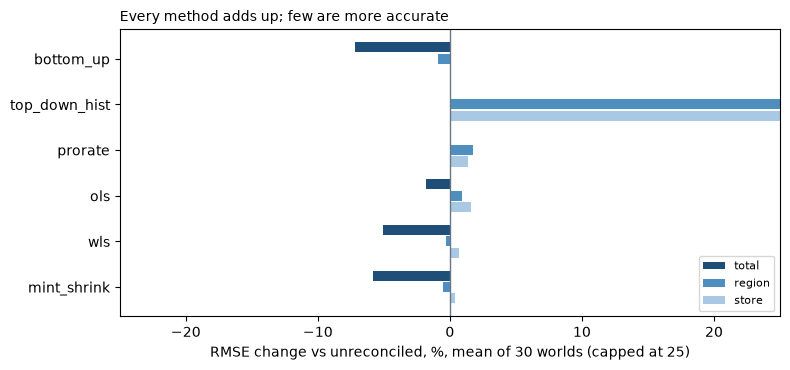

In [8]:
names = [m for m in METHODS if m != "base"][::-1]
cols = {"total": "#1f4e79", "region": "#4f8fc0", "store": "#a9c8e4"}
fig, ax = plt.subplots(figsize=(8, 3.8))
for i, m in enumerate(names):
    for j, lv in enumerate(LEVELS):
        v = 100 * s["mean"][m][lv]
        ax.barh(i + 0.25 - 0.25 * j, max(min(v, 25), -25), height=0.22, color=cols[lv], label=lv if i == 0 else None)
ax.axvline(0, color="#6b7684", lw=1)
ax.set_yticks(range(len(names)), names)
ax.set_xlim(-25, 25)
ax.set_xlabel("RMSE change vs unreconciled, %, mean of 30 worlds (capped at 25)")
ax.legend(loc="lower right", fontsize=8)
ax.set_title("Every method adds up; few are more accurate", loc="left", fontsize=10)
plt.tight_layout()
plt.savefig("notebook_chart.png", dpi=120)
plt.show()

## Summary

- Forecasts made level by level stop adding up as soon as any level is modelled differently (here: log scale).
- Splitting the top number by historical shares adds up and is the least accurate method when the mix drifts.
- Least-squares reconciliation gains a few percent at the top; no method improves all three levels reliably.
- Which level to trust is a backtest question: here the stores were the better forecasts, so bottom-up won the top.
- Reconciliation cannot add information: a shock no level's history contains stays a miss under every method.

## 8. Try your own

In [9]:
# w = make_world(seed=7, shock=0.25)          # another fictional retailer, one region cut 25%
# yhat, res = base_forecasts(w)
# print(reconcile(w, yhat, res, "mint_shrink")[:5].round(1))
# print(run(w)["wls"]["vs_base"])

---
Part of [phoebe-the-builder](https://github.com/phoebefu6/phoebe-the-builder). The Streamlit version reconciles the
retailer with any of the seven methods next to what happened: `pip install -r requirements.txt && streamlit run app.py`.